# 01 — Dữ liệu: GC10-DET và NEU-DET

(Nội dung viết ở các bước sau.)

In [1]:
# cell 0: provenance (run first)
import os, subprocess, sys
from pathlib import Path
ROOT = Path.cwd().resolve()
while not (ROOT / "main.py").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
os.chdir(ROOT); sys.path[:0] = [str(ROOT), str(ROOT / "scripts")]
git = lambda *a: subprocess.run(["git", *a], capture_output=True, text=True).stdout.strip()
print("commit", git("rev-parse", "--short", "HEAD"),
      "| code dirty", bool(git("status", "--porcelain", "--", ".", ":(exclude)runs", ":(exclude)notes")),
      "| features", Path("runs/inputs.txt").read_text().strip())

commit 82e6deb | code dirty False | features features/20261005_013042__gc10_fz_cls5first_img80pct/dino-vitb16


## Mục đích

Notebook này trả lời các câu hỏi về dữ liệu, trước khi nhìn tới mô hình:
1. Mỗi lớp có bao nhiêu ảnh, và lệch nhau đến mức nào?
2. Giao thức chia dữ liệu ra sao: train/test theo cuộn thép, S0 có nhãn, pool S1, các tập test?
3. Phần nào của dữ liệu không bao giờ được dùng?
4. Dữ liệu có vấn đề chất lượng gì: ảnh trùng, ảnh có nhiều lỗi, nhãn thư mục lệch với XML?
5. Vùng lỗi chiếm bao nhiêu phần của ảnh?

Nguồn: `splits/gc10_split.json` (sinh bởi `scripts/make_gc10_split.py`), `splits/neu_split.json`, ảnh gốc trong `datasets/`.

In [2]:
# A1: what is inside the GC10 split file
import json
split = json.loads(Path("splits/gc10_split.json").read_text())
print("keys:", list(split))
for k, v in split.items():
    if not isinstance(v, (dict, list)):
        print(f"  {k} = {v}")
cls, n_base = split["classes"], split["n_base"]
print(f"\n{len(cls)} classes, n_base = {n_base}")
print(f"{'class':16s} {'role':5s} {'train':>5s} {'test':>5s} {'n_use':>5s}")
for i, c in enumerate(cls):
    print(f"{c:16s} {'base' if i < n_base else 'novel':5s} {len(split['train'][c]):5d} {len(split['test'][c]):5d} {split['n_use'][c]:5d}")
tr = sum(len(split["train"][c]) for c in cls); te = sum(len(split["test"][c]) for c in cls)
print(f"total train {tr}, test {te}, all {tr + te}")

keys: ['root', 'classes', 'folders', 'n_base', 'seed', 'labeled_frac', 'test_frac_max', 'split_by', 'removed_duplicates', 'train', 'test', 'n_use', 'diagnostics']
  root = datasets/GC10-DET
  n_base = 5
  seed = 0
  labeled_frac = 0.8
  test_frac_max = 0.2
  split_by = coil = 3rd filename field

10 classes, n_base = 5
class            role  train  test n_use
punching_hole    base    172    43   137
welding_line     base    213    54   170
crescent_gap     base    179    45   143
water_spot       base    230    58   184
oil_spot         base    163    41   130
silk_spot        novel   526   124   420
inclusion        novel   169    43   135
rolled_pit       novel    22     6    17
crease           novel    41    11    32
waist_folding    novel   118    30    94
total train 1833, test 455, all 2288


### Nhận xét A1

- Các con số nền khớp: train 1833, test 455, tổng 2288 (= 2312 − 24 ảnh trùng); S0 = 764 ảnh có nhãn của 5 lớp cơ sở; pool S1 gồm 698 ảnh của 5 lớp mới.
- Train và test được chia theo cuộn thép (coil, trường thứ 3 trong tên file), nên ảnh của cùng một cuộn không nằm ở cả hai phía.
- `n_use` = 80% số ảnh train của mỗi lớp (`labeled_frac`). Với lớp cơ sở, đây là phần có nhãn ở S0. Với lớp mới, đây là phần xuất hiện ở S1.

In [3]:
# B1: imbalance and data usage per class (train split)
import numpy as np
rows = []
for i, c in enumerate(cls):
    n_tr, n_te, n_u = len(split["train"][c]), len(split["test"][c]), split["n_use"][c]
    used = n_u + (10 if i < n_base else 0)   # base: S0 labeled + 10 old samples drawn into the S1 pool (748 - 698 = 50)
    rows.append((n_tr, n_u, used))
    print(f"{c:16s} test {n_te / (n_tr + n_te):5.1%}   used {used:4d}/{n_tr:4d}   unused {n_tr - used:3d}")
cv = lambda x: np.std(x, ddof=1) / np.mean(x)   # coefficient of variation, sample std (n-1)
n_tr, n_u, used = (np.array(col) for col in zip(*rows))
print(f"\ntrain max/min = {n_tr.max()}/{n_tr.min()} = {n_tr.max() / n_tr.min():.1f}x")
print(f"CV of class sizes: all train {cv(n_tr):.2f} | base n_use {cv(n_u[:n_base]):.2f} | novel n_use (S1 pool) {cv(n_u[n_base:]):.2f}")
print(f"used {used.sum()} / {n_tr.sum()} train images, never used {n_tr.sum() - used.sum()}")

punching_hole    test 20.0%   used  147/ 172   unused  25
welding_line     test 20.2%   used  180/ 213   unused  33
crescent_gap     test 20.1%   used  153/ 179   unused  26
water_spot       test 20.1%   used  194/ 230   unused  36
oil_spot         test 20.1%   used  140/ 163   unused  23
silk_spot        test 19.1%   used  420/ 526   unused 106
inclusion        test 20.3%   used  135/ 169   unused  34
rolled_pit       test 21.4%   used   17/  22   unused   5
crease           test 21.2%   used   32/  41   unused   9
waist_folding    test 20.3%   used   94/ 118   unused  24

train max/min = 526/22 = 23.9x
CV of class sizes: all train 0.75 | base n_use 0.15 | novel n_use (S1 pool) 1.17
used 1512 / 1833 train images, never used 321


### Nhận xét B1

- Tỷ lệ test mỗi lớp từ 19.1% (silk) đến 21.4% (rolled), vì chia nguyên cả cuộn thép. `test_frac_max` = 0.2 là mục tiêu, không phải trần cứng cho từng lớp.
- Test của lớp hiếm rất nhỏ (rolled 6 ảnh, crease 11 ảnh): một ảnh tương ứng 16.7 và 9.1 điểm recall, hay 3.33 và 1.82 điểm balanced novel (balanced accuracy chia đều cho 5 lớp mới; Brodersen et al. 2010). Đánh giá khâu khám phá nên đo trên pool S1 (đánh giá chuyển nạp, transductive; Vaze et al. 2022), còn test dùng làm rào chắn.
- Độ lệch nằm gần như toàn bộ ở phía lớp mới. Hệ số biến thiên (CV = s/x̄, s là độ lệch chuẩn mẫu) của kích thước lớp: 0.15 với 5 lớp cơ sở, 1.17 với pool S1; lớn nhất/nhỏ nhất = 526/22 ≈ 23.9 lần. Như vậy S0 là bài toán phân loại có nhãn gần cân bằng, còn khâu khám phá ở S1 gánh toàn bộ độ lệch. k-means có xu hướng tạo các cụm cỡ gần đều nhau (uniform effect; Xiong, Wu & Chen 2009): ở Q1, CV của cỡ cụm chỉ 0.22–0.48, trong khi CV của lớp thật là 1.17.
- 321/1833 ảnh train (17.5%) không bao giờ được dùng:
  - 143 ảnh lớp cơ sở: phần pool không được bốc làm ảnh cũ ở S1 (mỗi lớp chỉ bốc 10).
  - 178 ảnh lớp mới: phần 20% còn lại sau `n_use`, vì giao thức chỉ có 1 phiên. Riêng lớp hiếm mất rolled 5 ảnh, crease 9 ảnh.

## C. Chất lượng nhãn và kích thước vùng lỗi

- C1: các cờ chẩn đoán có sẵn trong file split (ảnh có nhiều loại lỗi; nhãn thư mục không có trong XML; thiếu XML), tách theo lớp và vai trò (S0, S1, phần còn lại, test).
- C2: đọc hộp lỗi trong XML của ảnh S0 và S1, để biết loại lỗi nào hay xuất hiện chung và hộp lỗi chiếm bao nhiêu phần trăm diện tích ảnh.
- Quy tắc đọc XML giống hệt `scripts/make_gc10_split.py`: thư mục `label/`, chuẩn hoá `10_yaozhed`, bỏ đối tượng tên `d`.

In [4]:
# C1: data-quality flags (split diagnostics) by class and role
diag = {k: set(v) for k, v in split["diagnostics"].items()}
print({k: len(v) for k, v in diag.items()})
roles = {}                                     # "folder/name" -> (class, role)
for i, c in enumerate(cls):
    for j, p in enumerate(split["train"][c]):
        roles[p] = (c, ("S0" if i < n_base else "S1") if j < split["n_use"][c] else "rest")
    for p in split["test"][c]:
        roles[p] = (c, "test")
print(f"{'class':16s} {'role':4s} {'n':>4s} {'multi':>5s} {'not_in_xml':>10s} {'no_xml':>6s}")
for c in cls:
    for r in ("S0", "S1", "rest", "test"):
        ps = [p for p, (cc, rr) in roles.items() if cc == c and rr == r]
        if ps:
            print(f"{c:16s} {r:4s} {len(ps):4d} {sum(p in diag['multi_defect'] for p in ps):5d} "
                  f"{sum(p in diag['folder_not_in_xml'] for p in ps):10d} {sum(p in diag['no_xml'] for p in ps):6d}")

{'multi_defect': 466, 'folder_not_in_xml': 75, 'no_xml': 6}
class            role    n multi not_in_xml no_xml
punching_hole    S0    137    86          0      0
punching_hole    rest   35    27          0      0
punching_hole    test   43    31          0      0
welding_line     S0    170    85          1      0
welding_line     rest   43    19          0      0
welding_line     test   54    19          1      0
crescent_gap     S0    143    76          0      0
crescent_gap     rest   36    24          0      0
crescent_gap     test   45    24          0      0
water_spot       S0    184    13         18      0
water_spot       rest   46     7          4      0
water_spot       test   58     2          5      0
oil_spot         S0    130    10          7      0
oil_spot         rest   33     4          0      0
oil_spot         test   41     2          0      0
silk_spot        S1    420     3          2      0
silk_spot        rest  106     1          0      1
silk_spot        test 

In [5]:
# C2: XML boxes of S0 + S1 images: co-occurring defect types and own-box size
import collections
import xml.etree.ElementTree as ET
NORM = {"10_yaozhed": "10_yaozhe"}                       # same rule as scripts/make_gc10_split.py
fid = {f: i for i, f in enumerate(split["folders"])}      # folder "1".."10" -> class id
def types_boxes(xml_path):
    root = ET.parse(xml_path).getroot()
    W, H = float(root.findtext("size/width")), float(root.findtext("size/height"))
    out = []
    for o in root.iter("object"):
        j = fid.get(NORM.get(o.findtext("name"), o.findtext("name")).split("_")[0])
        if j is None:                                      # "d" and unknown names
            continue
        b = o.find("bndbox")
        w = float(b.findtext("xmax")) - float(b.findtext("xmin")); h = float(b.findtext("ymax")) - float(b.findtext("ymin"))
        out.append((j, w * h / (W * H) if W * H else np.nan))
    return out
co = np.zeros((len(cls), len(cls)), int)                   # co[i, j]: images of class i whose XML also has type j
area = collections.defaultdict(list)                       # class -> own-box area / image area
for p, (c, r) in roles.items():
    x = Path(split["root"]) / "label" / (Path(p).stem + ".xml")
    if r not in ("S0", "S1") or not x.exists():
        continue
    i, tb = cls.index(c), types_boxes(x)
    area[c] += [a for j, a in tb if j == i]
    for j in {j for j, _ in tb} - {i}:
        co[i, j] += 1
for i, c in enumerate(cls):
    a = np.array(area[c]) * 100
    top = sorted(((int(co[i, j]), cls[j]) for j in range(len(cls)) if co[i, j]), reverse=True)[:3]
    print(f"{c:16s} own boxes {len(a):4d} | area % median {np.nanmedian(a):5.1f} "
          f"[q1 {np.nanpercentile(a, 25):4.1f}, q3 {np.nanpercentile(a, 75):5.1f}] | also has {top}")

punching_hole    own boxes  137 | area % median   0.3 [q1  0.3, q3   0.3] | also has [(67, 'welding_line'), (19, 'silk_spot'), (9, 'crescent_gap')]
welding_line     own boxes  170 | area % median   6.7 [q1  4.7, q3   7.7] | also has [(71, 'punching_hole'), (14, 'crescent_gap'), (5, 'silk_spot')]
crescent_gap     own boxes  144 | area % median   5.9 [q1  3.3, q3   8.4] | also has [(74, 'welding_line'), (3, 'punching_hole'), (2, 'silk_spot')]
water_spot       own boxes  187 | area % median   5.2 [q1  2.3, q3  11.1] | also has [(18, 'oil_spot'), (13, 'silk_spot')]
oil_spot         own boxes  304 | area % median   0.5 [q1  0.2, q3   1.0] | also has [(7, 'water_spot'), (6, 'silk_spot'), (4, 'inclusion')]
silk_spot        own boxes  496 | area % median   8.3 [q1  3.4, q3  17.6] | also has [(5, 'oil_spot')]
inclusion        own boxes  199 | area % median   0.2 [q1  0.1, q3   0.6] | also has [(23, 'water_spot'), (13, 'silk_spot'), (1, 'rolled_pit')]
rolled_pit       own boxes   37 | area % med

### Nhận xét C

1. Ảnh nhiều lỗi tập trung ở lớp cơ sở.
   - punching, welding, crescent: 50–63% ảnh S0 có thêm loại lỗi khác, chủ yếu đi chung với nhau (welding–punching 67–71 ảnh, crescent–welding 74).
   - Pool S1 chỉ có 25/698 ảnh nhiều lỗi, trong đó inclusion chiếm 20.
   - [SUY LUẬN] Một phần nhầm lẫn giữa các lớp cơ sở (welding → crescent, punching) đến từ việc gán một nhãn duy nhất cho ảnh có nhiều lỗi, không hẳn là lỗi của mô hình.
2. Inclusion có nhãn kém tin cậy nhất trong S1.
   - 18/135 ảnh có nhãn thư mục không nằm trong XML, 20/135 ảnh nhiều lỗi; hay đi chung với water_spot (23 ảnh).
   - Đọc recall của inclusion phải thận trọng.
3. Crease và rolled gần như sạch.
   - Ảnh nhiều lỗi: 2/32 và 0/17. Lệch XML: 3/32 và 1/17.
   - Không đi chung với waist_folding: ảnh crease có waist 0; ảnh waist có crease 2.
   - Vậy việc Q1 thấy hai lớp này nằm trong cụm của waist không giải thích được bằng nhãn mơ hồ. Q5 không đổi cách đọc Q1 cho hai lớp này, và kết luận của PL-E01 về chúng không bị nhiễu nhãn chi phối.
4. Kích thước vùng lỗi rất khác nhau.
   - Median diện tích hộp so với cả ảnh: inclusion 0.2%, punching 0.3%, oil 0.5%, rolled 1.3%, crease 3.3%, water 5.2%, crescent 5.9%, welding 6.7%, silk 8.3%, waist 34.2%.
   - Quy đổi ra patch: ViT-B/16 ở 224×224 có 196 patch, nên 1 patch = 1/196 ≈ 0.51% diện tích ảnh. Resize 2048×1000 → 224×224 làm méo tỉ lệ khung (trục ngang co 9.1 lần, trục dọc 4.5 lần) nhưng giữ nguyên tỉ lệ diện tích. Ví dụ inclusion: 0.2% × 196 ≈ 0.4 patch; tương tự rolled ≈ 2.5, crease ≈ 6.5, waist ≈ 67 patch.
   - Lớp mới càng nhỏ thì recall của pipeline càng thấp: waist 97, silk 66, inclusion 14, crease 11, rolled 0. Spearman ρ = 0.7 với n = 5, nên chỉ là xu hướng, chưa đủ để kết luận.
   - Probe tuyến tính vẫn đạt 45–67 cho các lớp nhỏ, nên thông tin có trong đặc trưng nhưng yếu. [SUY LUẬN] Phân cụm không giám sát trên đặc trưng của cả ảnh dễ bị phần nền lấn át.
5. Cảnh báo cho ý tưởng crop theo hộp XML.
   - Hộp lỗi của lớp mới là một dạng nhãn, nên dùng nó trong GCD là rò rỉ nhãn. Nó chỉ dùng được làm cận trên (oracle).
   - Phiên bản dùng được phải tự định vị vùng lỗi mà không cần nhãn, ví dụ dùng patch token hoặc bản đồ bất thường (anomaly map).

## D. Ảnh mẫu: mô hình thực sự nhìn thấy gì

Mỗi lớp lấy ảnh đầu tiên trong phần S0 hoặc S1 có hộp lỗi của chính lớp đó. Thứ tự trong split đã là một hoán vị ngẫu nhiên với seed 0, nên đây là một mẫu ngẫu nhiên.
- Bên trái: ảnh gốc 2048×1000. Hộp đỏ là lỗi của chính lớp; hộp vàng là loại lỗi khác có trong cùng ảnh.
- Bên phải: ảnh 224×224 mà bộ trích đặc trưng đóng băng nhận vào (`--resize full`), kèm lưới 16×16 pixel. Mỗi ô lưới là một patch của ViT-B/16.
- Hình chỉ minh hoạ một ảnh mỗi lớp. Số liệu đại diện là median diện tích ở C2.

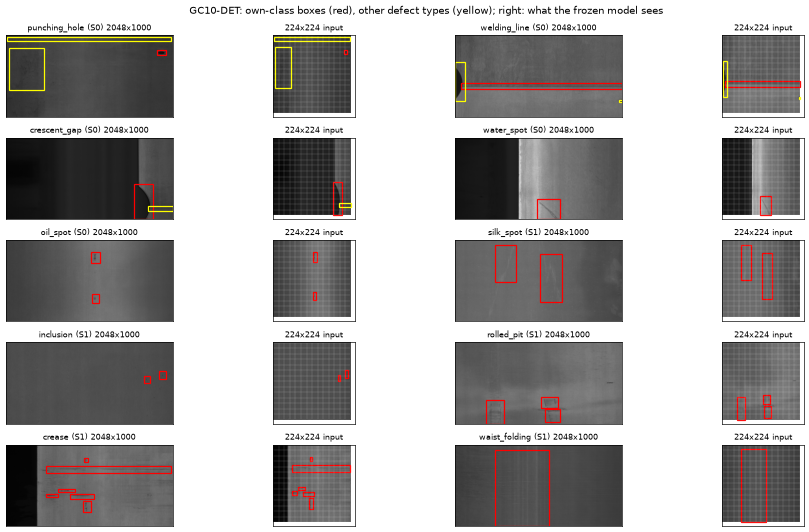

In [6]:
# D1: one S0/S1 image per class: original with boxes (left), the 224x224 frozen-model input with the patch grid (right)
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from PIL import Image
def boxes(xml_path):
    out = []
    for o in ET.parse(xml_path).getroot().iter("object"):
        j = fid.get(NORM.get(o.findtext("name"), o.findtext("name")).split("_")[0])
        if j is not None:
            b = o.find("bndbox")
            out.append((j, *(float(b.findtext(k)) for k in ("xmin", "ymin", "xmax", "ymax"))))
    return out
fig, axes = plt.subplots(5, 4, figsize=(16, 9), dpi=60)
for i, c in enumerate(cls):
    for p in split["train"][c][:split["n_use"][c]]:            # S0 (base) or S1 (novel) part, random order (seed 0)
        x = Path(split["root"]) / "label" / (Path(p).stem + ".xml")
        if x.exists() and any(j == i for j, *_ in boxes(x)):
            break
    img = Image.open(Path(split["root"]) / p).convert("RGB"); W, H = img.size
    small = img.resize((224, 224), Image.BILINEAR)
    for k, (im, sx, sy) in enumerate(((img, 1, 1), (small, 224 / W, 224 / H))):
        ax = axes[i // 2, 2 * (i % 2) + k]
        ax.imshow(im); ax.set_xticks([]); ax.set_yticks([])
        for j, x0, y0, x1, y1 in boxes(x):
            ax.add_patch(Rectangle((x0 * sx, y0 * sy), (x1 - x0) * sx, (y1 - y0) * sy, fill=False,
                                   edgecolor="red" if j == i else "yellow", linewidth=1.5))
        if k == 1:                                             # ViT-B/16 patch grid: 14 x 14 cells of 16 px
            ax.vlines(range(0, 225, 16), 0, 223, colors="white", linewidth=0.3, alpha=0.5)
            ax.hlines(range(0, 225, 16), 0, 223, colors="white", linewidth=0.3, alpha=0.5)
        ax.set_title(f"{c} ({'S0' if i < n_base else 'S1'}) {W}x{H}" if k == 0 else "224x224 input", fontsize=10)
fig.suptitle("GC10-DET: own-class boxes (red), other defect types (yellow); right: what the frozen model sees", fontsize=12)
plt.tight_layout(); plt.show()

### Nhận xét D (một ảnh mỗi lớp, chỉ để minh hoạ)

1. Trên ảnh 224×224, hộp lỗi của inclusion, punching và oil nằm gọn trong khoảng một ô patch; mỗi hộp của rolled chiếm 1–2 ô; waist phủ phần lớn ảnh. Khớp với C4.
2. Resize làm méo tỉ lệ khung: trục ngang co 9.1 lần, trục dọc chỉ co 4.5 lần. Vì vậy lỗi dạng vệt ngang (welding_line, vệt dài của crease) bị nén mạnh hơn lỗi dạng vệt dọc (silk).
3. Ảnh của lớp cơ sở có hộp vàng, tức loại lỗi khác nằm trong cùng ảnh. Khớp với C1.
4. [SUY LUẬN] Nền thay đổi mạnh giữa các ảnh (dải tối ở mép tấm, các vùng sáng tối khác nhau) và chiếm phần lớn diện tích ảnh. Với lỗi nhỏ, đặc trưng của cả ảnh có thể mã hoá nền nhiều hơn mã hoá lỗi. Đây là giả thuyết cần đo, chưa phải kết luận. Lưu ý: trước đây chuẩn hoá theo camera (Q9 của dòng cũ) không cải thiện vượt mức nhiễu, nên nếu nền có ảnh hưởng thì ảnh hưởng đó không chỉ là độ lệch theo camera.

## E. NEU-DET: đối chứng dễ

NEU-DET chỉ dùng để kiểm tính đúng đắn, vì đã chạm trần (lớp mới đạt 100%). Phần này so hai điều với GC10: độ cân bằng giữa các lớp, và kích thước vùng lỗi.

In [7]:
# E1: NEU-DET protocol and box size, for contrast with GC10
neu = json.loads(Path("splits/neu_split.json").read_text())
ncls = neu["classes"]; nb = neu.get("n_base", len(ncls) // 2)
nu = {c: int(neu["labeled_frac"] * len(neu["train"][c])) for c in ncls}
for i, c in enumerate(ncls):
    print(f"{c:16s} {'base' if i < nb else 'novel':5s} train {len(neu['train'][c]):3d} (n_use {nu[c]}) test {len(neu['test'][c]):3d}")
xmls = {p.stem: p for p in Path(neu["root"]).rglob("*.xml")}
print(f"\n{len(xmls)} XML files under {neu['root']}")
for c in ncls:
    a = []
    for name in neu["train"][c][:nu[c]]:
        x = xmls.get(Path(name).stem)
        if x is None:
            continue
        root = ET.parse(x).getroot()
        W, H = float(root.findtext("size/width")), float(root.findtext("size/height"))
        for o in root.iter("object"):
            if o.findtext("name") == c:
                b = o.find("bndbox")
                a.append((float(b.findtext("xmax")) - float(b.findtext("xmin"))) * (float(b.findtext("ymax")) - float(b.findtext("ymin"))) / (W * H))
    a = np.array(a) * 100
    if len(a):
        print(f"{c:16s} own boxes {len(a):4d} | area % median {np.median(a):5.1f} [q1 {np.percentile(a, 25):4.1f}, "
              f"q3 {np.percentile(a, 75):5.1f}] | ~{np.median(a) * 1.96:.0f} patches (ignores the 256->224 crop)")

crazing          base  train 240 (n_use 192) test  60
inclusion        base  train 240 (n_use 192) test  60
patches          base  train 240 (n_use 192) test  60
pitted_surface   novel train 240 (n_use 192) test  60
rolled-in_scale  novel train 240 (n_use 192) test  60
scratches        novel train 240 (n_use 192) test  60

1800 XML files under datasets/NEU-DET
crazing          own boxes  415 | area % median  20.1 [q1 14.9, q3  28.7] | ~39 patches (ignores the 256->224 crop)
inclusion        own boxes  594 | area % median   4.5 [q1  2.3, q3  11.2] | ~9 patches (ignores the 256->224 crop)
patches          own boxes  516 | area % median  10.5 [q1  6.2, q3  19.8] | ~20 patches (ignores the 256->224 crop)
pitted_surface   own boxes  277 | area % median  54.8 [q1 34.2, q3  87.2] | ~107 patches (ignores the 256->224 crop)
rolled-in_scale  own boxes  397 | area % median  11.8 [q1  6.8, q3  18.9] | ~23 patches (ignores the 256->224 crop)
scratches        own boxes  337 | area % median   7.4 [q1